

**План ноутбука**:
1. Данные (FLEURS, русская часть) и их разведочный анализ (EDA)
2. Разбиение на обучение / проверку / тест, защита от утечки данных
3. Reference-точки: константный ответ и Whisper без обучения
4. Дообучение на PyTorch (код и журнал обучения), кривые обучения
5. Результаты на тесте, доверительные интервалы, сравнение по фразам
6. Анализ ошибок и интерпретация модели (cross-attention)
7. Классическая модель: какие расшифровки ненадёжны
8. Демонстрация на новой записи, выводы, ограничения



In [1]:
import copy, difflib, html, json, os, random, re, subprocess, tempfile, time
from pathlib import Path

os.environ["HF_HUB_DISABLE_XET"] = "1"                       # обычная загрузка файлов с Hugging Face
os.environ["PATH"] = "/opt/homebrew/bin:" + os.environ.get("PATH", "")      # ffmpeg для демонстрации в конце

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torch.nn.functional as F
import jiwer
from IPython.display import Audio, HTML, display
from transformers import WhisperForConditionalGeneration, WhisperProcessor, get_linear_schedule_with_warmup
from transformers.models.whisper.english_normalizer import BasicTextNormalizer

SEED = 42
RETRAIN = False                 # True: обучить заново (около 35 минут); False: взять сохранённый журнал и чекпоинт
ROOT = Path.cwd()
DATA, RESULTS, MODELS = ROOT / "data", ROOT / "results", ROOT / "models"
for d in (DATA, RESULTS, MODELS):
    d.mkdir(exist_ok=True)
WHISPER = "openai/whisper-base"
LANG_NAME, TASK = "russian", "transcribe"
N_TRAIN, N_VAL, N_TEST, MAX_SECONDS = 1500, 300, 500, 30.0          # размеры выборок и окно Whisper (30 с)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


set_seed()
NORM = BasicTextNormalizer(remove_diacritics=False)          # нижний регистр, без знаков препинания; «й» и «ё» остаются разными буквами
print("устройство:", DEVICE, "| torch", torch.__version__, "| seed", SEED, "| RETRAIN =", RETRAIN)

/Users/david/Desktop/ml final/whisper-finetune/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1123 20:46:45.519000 83264 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


устройство: mps | torch 2.15.0 | seed 42 | RETRAIN = False


## 1. Данные

**FLEURS** (Google), русская часть `ru_ru`, лицензия CC BY 4.0: реальные записи носителей языка, которые читают предложения (в основном из Википедии). Правильный текст дан к каждой записи. Синтетических данных нет. Дикторы в официальных частях train / dev / test **разные**, поэтому один и тот же голос не попадёт и в обучение, и в тест.

In [2]:
RAW = DATA / "raw"
if not (RAW / "audio" / "test").exists():                    # скачать, если ещё нет (около 2 ГБ)
    import tarfile
    from huggingface_hub import hf_hub_download
    RAW.mkdir(parents=True, exist_ok=True)
    for split in ("train", "dev", "test"):
        tsv = hf_hub_download("google/fleurs", f"data/ru_ru/{split}.tsv", repo_type="dataset")
        (RAW / f"{split}.tsv").write_bytes(open(tsv, "rb").read())
        arc = hf_hub_download("google/fleurs", f"data/ru_ru/audio/{split}.tar.gz", repo_type="dataset")
        with tarfile.open(arc) as t:
            t.extractall(RAW / "audio", filter="data")
else:
    print("данные уже скачаны:", RAW)

COLS = ["id", "file_name", "raw_transcription", "transcription", "chars", "num_samples", "gender"]
tsv = {s: pd.read_csv(RAW / f"{s}.tsv", sep="\t", header=None, names=COLS, quoting=3) for s in ("train", "dev", "test")}
for s, d in tsv.items():
    d["split"], d["seconds"] = s, d.num_samples / 16000
    d["words"] = d.transcription.astype(str).str.split().str.len()
    d["path"] = [str(RAW / "audio" / s / f) for f in d.file_name]
all_ = pd.concat(tsv.values(), ignore_index=True)
print("Размеры официальных частей:")
display(pd.DataFrame({"записей": {s: len(d) for s, d in tsv.items()}, "часов": {s: round(d.seconds.sum() / 3600, 2) for s, d in tsv.items()}}))
print("Первые строки (вход: аудио, цель: правильный текст):")
display(tsv["train"][["file_name", "raw_transcription", "seconds", "gender"]].head(5))
row = tsv["train"].iloc[3]
audio, sr = sf.read(row.path, dtype="float32")
print(f"Пример записи ({row.seconds:.1f} с): «{row.raw_transcription}»")
Audio(audio, rate=sr)

данные уже скачаны: /Users/david/Desktop/ml final/whisper-finetune/data/raw
Размеры официальных частей:


,записей,часов
train,2562,8.05
dev,356,1.08
test,775,2.50


Первые строки (вход: аудио, цель: правильный текст):


,file_name,raw_transcription,seconds,gender
0,16478509024581879724.wav,К 17 сентября 1939 года польская оборона уже б...,27.84,FEMALE
1,7494180618733873687.wav,"Многие билеты, которые продаются в Интернете ч...",19.86,FEMALE
2,11150700604967895355.wav,"Так вы как можно меньше устанете. Запомните, ч...",8.16,MALE
3,1631268539706013390.wav,Оставленный без присмотра багаж представляет с...,11.16,FEMALE
4,15708446496250705742.wav,"Знак движения смычка вверх выглядит как V, а д...",9.90,MALE


Пример записи (11.2 с): «Оставленный без присмотра багаж представляет собой мишень для воров, а также может привлечь внимание органов безопасности, которые опасаются угрозы теракта.»


## 2. Разведочный анализ (EDA)

,значение
пропущенных значений,0.00
записей длиннее 30 с (окно Whisper),3.00
"доля предложений с цифрами, %",18.80
"доля предложений с латиницей, %",8.30
"медиана длины записи, с",10.70
медиана слов в предложении,18.00
"медиана скорости речи, слов/с",1.71


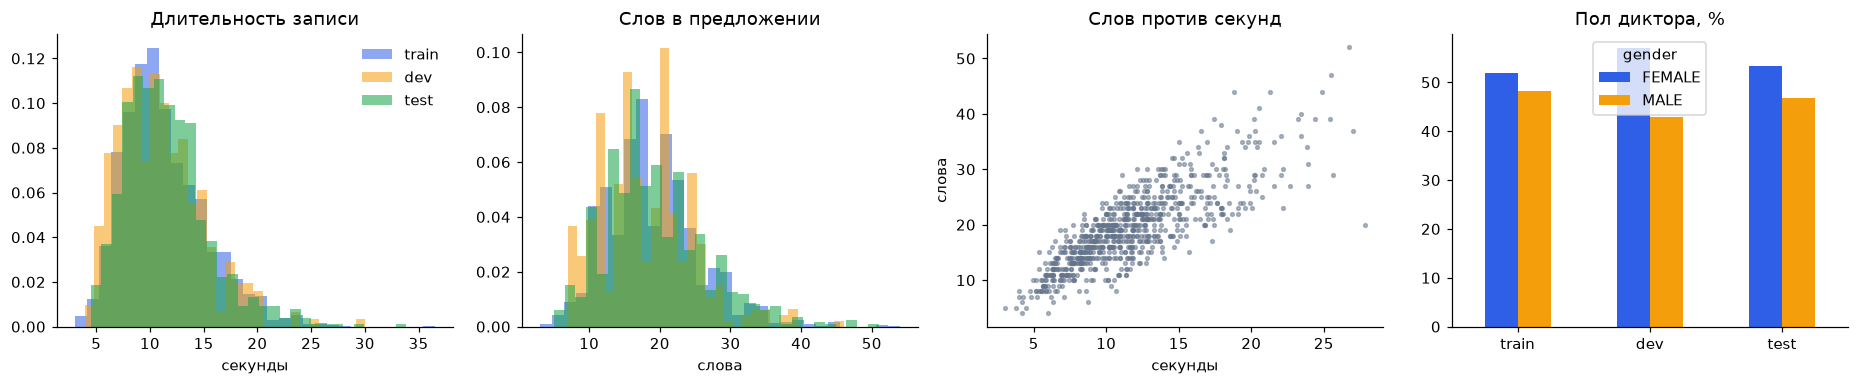

In [3]:
stats = {"пропущенных значений": int(all_[["raw_transcription", "transcription", "num_samples", "gender"]].isna().sum().sum()),
         "записей длиннее 30 с (окно Whisper)": int((all_.seconds > 30).sum()),
         "доля предложений с цифрами, %": round(float(all_.raw_transcription.astype(str).str.contains(r"\d").mean() * 100), 1),
         "доля предложений с латиницей, %": round(float(all_.raw_transcription.astype(str).str.contains(r"[A-Za-z]").mean() * 100), 1),
         "медиана длины записи, с": round(float(all_.seconds.median()), 1), "медиана слов в предложении": float(all_.words.median()),
         "медиана скорости речи, слов/с": round(float((all_.words / all_.seconds).median()), 2)}
display(pd.Series(stats, name="значение").to_frame())

fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for s, c in zip(("train", "dev", "test"), ("#2f5fe6", "#f59e0b", "#16a34a")):
    ax[0].hist(tsv[s].seconds, bins=30, alpha=.55, color=c, label=s, density=True); ax[1].hist(tsv[s].words, bins=30, alpha=.55, color=c, density=True)
ax[0].set_title("Длительность записи"); ax[0].set_xlabel("секунды"); ax[0].legend(frameon=False)
ax[1].set_title("Слов в предложении"); ax[1].set_xlabel("слова")
smp = all_.sample(800, random_state=SEED); ax[2].scatter(smp.seconds, smp.words, s=6, alpha=.5, color="#64748b"); ax[2].set_title("Слов против секунд"); ax[2].set_xlabel("секунды"); ax[2].set_ylabel("слова")
g = pd.crosstab(all_.split, all_.gender, normalize="index").reindex(["train", "dev", "test"]) * 100
g.plot.bar(ax=ax[3], color=["#2f5fe6", "#f59e0b"], rot=0); ax[3].set_title("Пол диктора, %"); ax[3].set_xlabel("")
plt.tight_layout(); plt.show()

**Что видно и как это повлияло на решения**
- Записи длятся 3–37 с (медиана 10,6 с), около 18 слов, скорость речи стабильна (1,7 слова/с). Пропусков нет. **Решение:** записи длиннее 30 с (окно Whisper) отбрасываем.
- Около 19 % предложений содержат цифры и 8 % латиницу (названия). **Решение:** ошибки для этих случаев считаем и отдельно.
- Дикторы в частях разные, пол сбалансирован (52 % / 48 %). **Решение:** используем официальные разбиения как есть, а не перемешиваем случайно.
- Ограничения данных: читаемая речь в тишине, энциклопедические предложения, один домен; это не живой урок.

## 3. Разбиение и защита от утечки данных
Берём случайные подвыборки (seed 42) из **официальных** частей: 1500 записей на обучение, 300 на проверку (выбор эпохи), 500 на тест (используется один раз, в конце). Дополнительно проверяем, что ни одно предложение и ни один файл не встречаются в двух частях.

In [4]:
frames = {}
for s in ("train", "dev", "test"):
    d = tsv[s].copy(); d["text"] = d.raw_transcription.astype(str).str.strip()
    frames[s] = d[d.seconds <= MAX_SECONDS]
held = set(frames["dev"].text.map(NORM)) | set(frames["test"].text.map(NORM))
train_all = frames["train"][~frames["train"].text.map(NORM).isin(held)]
sub = {"train": train_all.sample(N_TRAIN, random_state=SEED), "val": frames["dev"].sample(N_VAL, random_state=SEED), "test": frames["test"].sample(N_TEST, random_state=SEED)}
(DATA / "processed").mkdir(exist_ok=True)
for name, d in sub.items():
    d[["id", "path", "text", "seconds", "gender"]].to_csv(DATA / "processed" / f"{name}.csv", index=False)
leak = {"пересечение предложений train/val": len(set(sub["train"].text.map(NORM)) & set(sub["val"].text.map(NORM))),
        "пересечение предложений train/test": len(set(sub["train"].text.map(NORM)) & set(sub["test"].text.map(NORM))),
        "пересечение файлов": len(set(sub["train"].file_name) & (set(sub["val"].file_name) | set(sub["test"].file_name)))}
assert all(v == 0 for v in leak.values()), "утечка данных"
display(pd.DataFrame({"записей": {k: len(v) for k, v in sub.items()}, "часов": {k: round(v.seconds.sum() / 3600, 2) for k, v in sub.items()}}))
print("Проверка утечки:", leak)
train, val, test = (pd.read_csv(DATA / "processed" / f"{n}.csv") for n in ("train", "val", "test"))

,записей,часов
train,1500,4.70
val,300,0.91
test,500,1.60


Проверка утечки: {'пересечение предложений train/val': 0, 'пересечение предложений train/test': 0, 'пересечение файлов': 0}


## 4. Вспомогательные функции: чтение звука, декодирование, WER
Одна и та же реализация метрики используется для **всех** моделей.

In [5]:
proc = WhisperProcessor.from_pretrained(WHISPER, language=LANG_NAME, task=TASK)
proc.tokenizer.set_prefix_tokens(language=LANG_NAME, task=TASK, predict_timestamps=False)


def read_audio(path):
    a, sr = sf.read(path, dtype="float32"); assert sr == 16000
    return a.mean(axis=1) if a.ndim > 1 else a


def features(paths):                                     # лог-мел-спектрограмма 80 x 3000 (30 секунд)
    return proc.feature_extractor([read_audio(p) for p in paths], sampling_rate=16000, return_tensors="pt").input_features


def load_model(path=WHISPER, **kw):
    m = WhisperForConditionalGeneration.from_pretrained(path, **kw)
    m.generation_config.forced_decoder_ids = None
    return m.to(DEVICE)


@torch.no_grad()
def transcribe(model, paths, batch_size=16):
    model.eval(); out = []
    for i in range(0, len(paths), batch_size):
        ids = model.generate(input_features=features(paths[i:i + batch_size]).to(DEVICE), language=LANG_NAME, task=TASK, num_beams=1, max_new_tokens=200)
        out += [t.strip() for t in proc.batch_decode(ids, skip_special_tokens=True)]
    return out


def word_errors(refs, hyps):
    errs, nw, ce, nc = [], [], [], []
    for r, h in zip(refs, hyps):
        r, h = NORM(r).strip(), NORM(h).strip()
        o = jiwer.process_words(r, h if h else "<empty>"); c = jiwer.process_characters(r, h if h else "_")
        errs.append(o.substitutions + o.deletions + o.insertions); nw.append(len(r.split()))
        ce.append(c.substitutions + c.deletions + c.insertions); nc.append(len(r))
    return np.array(errs), np.array(nw), np.array(ce), np.array(nc)


def wer(refs, hyps):
    e, n, _, _ = word_errors(refs, hyps); return float(e.sum() / n.sum())


# маленький тест метрики: 1 замена на 4 слова = 0.25
assert abs(wer(["я иду домой сейчас"], ["я иду домой сегодня"]) - 0.25) < 1e-9
print("WER реализован верно (проверка на примере)")

WER реализован верно (проверка на примере)


## 5. Reference-точки (baseline)
Прежде чем учить нейросеть, нужно знать, с чем сравнивать.
1. **Константный ответ**: на любую запись выдаём самое частое слово обучающих текстов. Это нижняя граница, любая осмысленная модель обязана её побить.
2. **Whisper-base без обучения (zero-shot)**: готовая модель, это отправная точка, от которой считается выигрыш дообучения.

In [6]:
from collections import Counter
common_word = Counter(w for t in train.text for w in NORM(t).split()).most_common(1)[0][0]
print("самое частое слово:", repr(common_word))

PRED = RESULTS / "predictions"; PRED.mkdir(exist_ok=True)
METRICS = {}


def record(name, split, df, hyps):
    e, n, ce, nc = word_errors(df.text.tolist(), hyps)
    out = df[["id", "text", "seconds", "gender"]].copy(); out["hyp"], out["word_errors"], out["ref_words"] = list(hyps), e, n
    out.to_csv(PRED / f"{name}__{split}.csv", index=False)
    METRICS.setdefault(name, {})[split] = {"n": len(df), "wer": round(float(e.sum() / n.sum()), 4), "cer": round(float(ce.sum() / nc.sum()), 4)}
    return METRICS[name][split]


for split, df in (("val", val), ("test", test)):
    record("constant_word", split, df, [common_word] * len(df))

t0 = time.time()
base = load_model(WHISPER)
for split, df in (("val", val), ("test", test)):
    print("Whisper-base без обучения,", split, record("whisper_base_zero_shot", split, df, transcribe(base, df.path.tolist())), f"{time.time() - t0:.0f} с")
display(pd.DataFrame({k: {s: v[s]["wer"] for s in v} for k, v in METRICS.items()}).T.rename_axis("модель"))

самое частое слово: 'в'



Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 245/245 [00:00<00:00, 12779.08it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


[transformers] The attention mask is not set with a batched input, and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (50 outputs left out)

[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Whisper-base без обучения, test {'n': 500, 'wer': 0.2476, 'cer': 0.0755} 75 с


,val,test
модель,,
constant_word,0.9733,0.9758
whisper_base_zero_shot,0.2345,0.2476


Константный ответ даёт WER около 0,97 (ошибочно почти каждое слово), готовый Whisper-base около 0,23 – 0,25. Дальше смотрим, сдвинет ли дообучение это число.

## 6. Дообучение на PyTorch

**Модель.** Whisper-base: энкодер читает лог-мел-спектрограмму (80 частотных полос), декодер пишет текст токен за токеном, на каждом шаге «глядя» на выход энкодера (cross-attention). 6 + 6 слоёв Transformer, скрытый размер 512, 8 голов, активация GELU, 74 млн параметров. Обучается **вся сеть**, а не только последний слой.

**Как учим (teacher forcing).** Декодеру подаём токены `<start> <ru> <transcribe> <notimestamps>` и правильный текст, сдвинутый на один токен; он должен предсказать следующий токен. Функция потерь: cross-entropy по токенам текста (три служебных токена языка и задачи исключены). Градиенты считает обратное распространение (autograd), шаг делает AdamW.

| Параметр | Значение | Зачем |
|---|---|---|
| learning rate | 1e-5 | маленький шаг, чтобы не «забыть» предобучение |
| optimizer | AdamW, weight decay 0,01 | регуляризация весов (кроме bias и LayerNorm) |
| расписание | 10 % разогрев, затем линейный спад | устойчивый старт |
| batch | 8 (2 микробатча по 4, накопление градиента) | ноутбук 16 ГБ, батч 8 за раз не помещался |
| эпохи | до 4, ранняя остановка по WER на валидации (patience 2) | защита от переобучения |
| clip градиента | 1,0 | защита от «взрыва» |
| SpecAugment | маски по времени и частоте 5 % | регуляризация аугментацией |
| dropout | выключен | с transformers 5.24 он поднимал потерю предобученной модели с 0,62 до ~11 ещё до обучения (проверено на одном батче) |
| seed | 42 | воспроизводимость |

In [7]:
BATCH, MICRO, MAX_EPOCHS, PATIENCE, WEIGHT_DECAY, WARMUP, LR = 8, 4, 4, 2, 0.01, 0.1, 1e-5
REG = dict(apply_spec_augment=True, mask_time_prob=0.05, mask_feature_prob=0.05)


def batch_tensors(df):
    ids = [proc.tokenizer(t).input_ids for t in df.text]            # <sot><ru><transcribe><notimestamps> текст <eot>
    L = max(map(len, ids))
    dec_in = torch.full((len(ids), L - 1), proc.tokenizer.pad_token_id); tgt = torch.full((len(ids), L - 1), -100)
    for j, x in enumerate(ids):
        dec_in[j, :len(x) - 1] = torch.tensor(x[:-1]); tgt[j, :len(x) - 1] = torch.tensor(x[1:]); tgt[j, :3] = -100      # без потерь на служебных токенах
    return features(df.path.tolist()).to(DEVICE), dec_in.to(DEVICE), tgt.to(DEVICE)


@torch.no_grad()
def val_loss(model, df):
    model.eval(); tot = n = 0
    for i in range(0, len(df), BATCH):
        f, d, t = batch_tensors(df.iloc[i:i + BATCH])
        lg = model(input_features=f, decoder_input_ids=d).logits.float()
        tot += float(F.cross_entropy(lg.reshape(-1, lg.size(-1)), t.reshape(-1), ignore_index=-100, reduction="sum")); n += int((t != -100).sum())
    return tot / n


def run_training(train_df, val_df, lr=LR):
    set_seed()
    model = load_model(WHISPER, **REG)
    no_decay = ["bias", "layer_norm", "LayerNorm"]
    groups = [{"params": [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)], "weight_decay": WEIGHT_DECAY},
              {"params": [p for n, p in model.named_parameters() if any(k in n for k in no_decay)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups, lr=lr)
    steps = MAX_EPOCHS * int(np.ceil(len(train_df) / BATCH))
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP * steps), steps)
    gen = torch.Generator().manual_seed(SEED)
    hist, best, best_state, bad = [], 1e9, None, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train(); t0, tot, seen = time.time(), 0.0, 0
        order = torch.randperm(len(train_df), generator=gen).tolist()
        for i in range(0, len(order), BATCH):
            opt.zero_grad(); chunk = order[i:i + BATCH]
            for k in range(0, len(chunk), MICRO):
                sub = chunk[k:k + MICRO]
                f, d, t = batch_tensors(train_df.iloc[sub])
                lg = model(input_features=f, decoder_input_ids=d).logits.float()
                loss = F.cross_entropy(lg.reshape(-1, lg.size(-1)), t.reshape(-1), ignore_index=-100)
                (loss * len(sub) / len(chunk)).backward(); tot += loss.item() * len(sub); seen += len(sub)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
            if (i // BATCH + 1) % 25 == 0:
                print(f"эпоха {epoch}, шаг {i // BATCH + 1}/{int(np.ceil(len(order) / BATCH))}, loss {tot / seen:.3f}", flush=True)
        row = {"epoch": epoch, "train_loss": round(tot / seen, 4), "train_seconds": round(time.time() - t0, 1), "val_loss": round(val_loss(model, val_df), 4)}
        row["val_wer"] = round(wer(val_df.text.tolist(), transcribe(model, val_df.path.tolist())), 4)
        if row["val_wer"] < best:
            best, bad, best_state, row["best"] = row["val_wer"], 0, copy.deepcopy({k: v.cpu() for k, v in model.state_dict().items()}), True
        else:
            bad += 1
        hist.append(row); print(row, flush=True)
        if bad >= PATIENCE:
            break
    model.load_state_dict(best_state)
    return model, hist


CKPT = MODELS / "whisper-base-ru"
if RETRAIN or not CKPT.exists():
    print("Обучение с нуля...")
    ft, hist = run_training(train, val)
    ft.save_pretrained(CKPT); proc.save_pretrained(CKPT)
    best_ep = max(hist, key=lambda r: r.get("best", False) * r["epoch"])["epoch"]
    HIST = {"model": WHISPER, "device": str(DEVICE), "batch_size": BATCH, "weight_decay": WEIGHT_DECAY, "warmup_ratio": WARMUP, "regularisation": REG, "seed": SEED,
            "runs": [{"config": {"lr": LR}, "history": hist, "best_epoch": best_ep}], "selected": {"lr": LR, "best_epoch": best_ep}}
    (RESULTS / "finetune_history.json").write_text(json.dumps(HIST, indent=2))
else:
    print("Берём сохранённые результаты обучения (RETRAIN = False):", CKPT)
    HIST = json.loads((RESULTS / "finetune_history.json").read_text())
    ft = load_model(CKPT)
display(pd.DataFrame(HIST["runs"][0]["history"]).set_index("epoch"))
print("выбранная эпоха:", HIST["selected"]["best_epoch"], "| число параметров:", f"{sum(p.numel() for p in ft.parameters()) / 1e6:.1f} млн")

Берём сохранённые результаты обучения (RETRAIN = False): /Users/david/Desktop/ml final/whisper-finetune/models/whisper-base-ru



Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 245/245 [00:00<00:00, 11420.37it/s]

,train_loss,train_seconds,val_loss,val_wer,val_seconds,best
epoch,,,,,,
1,0.7020,427.6,0.3930,0.2349,38.1,True
2,0.4310,415.8,0.3803,0.2332,37.4,True
3,0.3192,403.0,0.3802,0.2358,39.2,NaN
4,0.2728,433.2,0.3812,0.2402,40.9,NaN


выбранная эпоха: 2 | число параметров: 72.6 млн


### Кривые обучения
Слева потеря (cross-entropy) на обучении и на проверке, справа WER на проверке по эпохам.

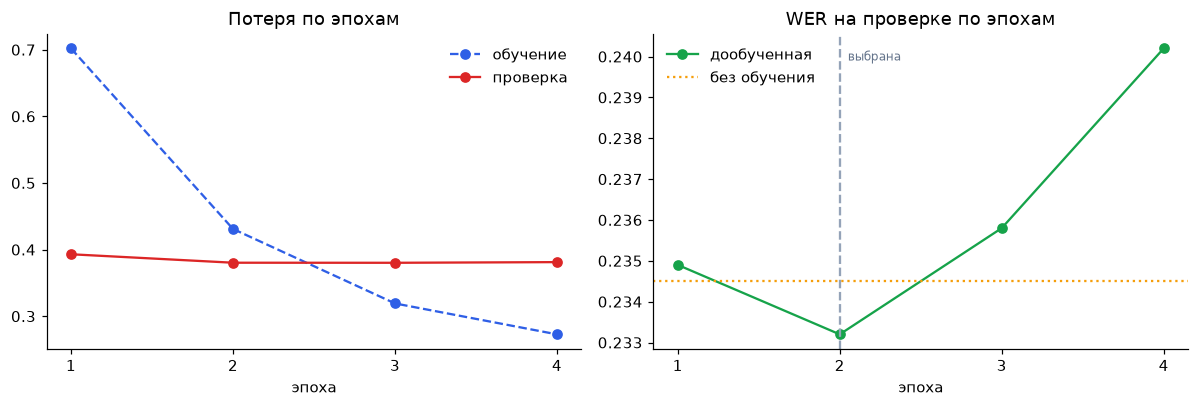

In [8]:
h = HIST["runs"][0]["history"]; ep = [r["epoch"] for r in h]; sel = HIST["selected"]["best_epoch"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ep, [r["train_loss"] for r in h], "--o", color="#2f5fe6", label="обучение"); ax[0].plot(ep, [r["val_loss"] for r in h], "-o", color="#dc2626", label="проверка")
ax[0].set_title("Потеря по эпохам"); ax[0].set_xlabel("эпоха"); ax[0].legend(frameon=False); ax[0].set_xticks(ep)
ax[1].plot(ep, [r["val_wer"] for r in h], "-o", color="#16a34a", label="дообученная"); ax[1].axhline(METRICS["whisper_base_zero_shot"]["val"]["wer"], color="#f59e0b", ls=":", label="без обучения")
ax[1].axvline(sel, color="#94a3b8", ls="--"); ax[1].text(sel + .05, ax[1].get_ylim()[1] - 0.0004, "выбрана", fontsize=8, color="#64748b", va="top")
ax[1].set_title("WER на проверке по эпохам"); ax[1].set_xlabel("эпоха"); ax[1].legend(frameon=False); ax[1].set_xticks(ep)
plt.tight_layout(); plt.savefig(RESULTS / "fig_learning_curves.png", dpi=160); plt.show()

**Что видно.** Потеря на обучении падает (0,70 → 0,27), а на проверке стоит около 0,38: после 2-й эпохи модель начинает **переобучаться** (WER на проверке растёт 0,2332 → 0,2358 → 0,2402). Ранняя остановка выбрала 2-ю эпоху. Недообучения нет: потеря на обучении сильно упала.

**О гиперпараметрах.** Планировалась сетка learning rate {1e-5, 3e-5}; из-за времени (≈ 35 минут на прогон на ноутбуке) был обучен только 1e-5, число эпох подобрано по проверке. Это ограничение честно записано в выводах.

## 7. Результаты на тесте
Тест (500 записей) использовался только здесь, для уже выбранной эпохи. Распознаём val и test дообученной моделью (около 1–2 минут).

[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (45 outputs left out)

[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


дообученная, test {'n': 500, 'wer': 0.2408, 'cer': 0.0757} 82 с


,WER val,WER test,95 % интервал test,CER val,CER test
модель,,,,,
Константный ответ,0.9733,0.9758,[0.973; 0.978],0.9922,0.9926
Whisper-base без обучения,0.2345,0.2476,[0.234; 0.262],0.0719,0.0755
Whisper-base дообученный,0.2332,0.2408,[0.228; 0.255],0.0697,0.0757


Выигрыш дообучения на тесте (WER без обучения минус WER дообученной): 0.0067, 95 % интервал [-0.0014; 0.0152]
Интервал включает ноль => выигрыш статистически незначим


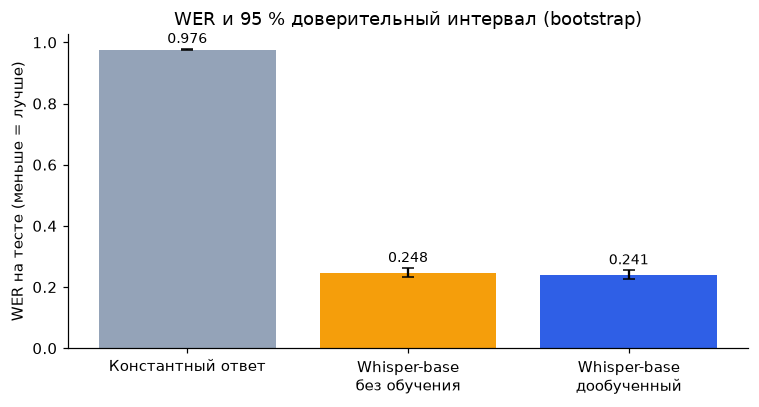

In [9]:
t0 = time.time()
for split, df in (("val", val), ("test", test)):
    print("дообученная,", split, record("whisper_base_finetuned", split, df, transcribe(ft, df.path.tolist())), f"{time.time() - t0:.0f} с")
(RESULTS / "metrics.json").write_text(json.dumps(METRICS, indent=2))

NAMES = {"constant_word": "Константный ответ", "whisper_base_zero_shot": "Whisper-base без обучения", "whisper_base_finetuned": "Whisper-base дообученный"}
P = {m: pd.read_csv(PRED / f"{m}__test.csv") for m in NAMES}
rng = np.random.default_rng(SEED)
N = len(P["whisper_base_zero_shot"]); boots = {m: [] for m in NAMES}; diff = []
for _ in range(1000):
    idx = rng.integers(0, N, N)
    for m in NAMES:
        boots[m].append(P[m].word_errors.to_numpy()[idx].sum() / P[m].ref_words.to_numpy()[idx].sum())
    diff.append(boots["whisper_base_zero_shot"][-1] - boots["whisper_base_finetuned"][-1])
ci = {m: [float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))] for m, b in boots.items()}
dci = [float(np.percentile(diff, 2.5)), float(np.percentile(diff, 97.5))]
table = pd.DataFrame([{"модель": NAMES[m], "WER val": METRICS[m]["val"]["wer"], "WER test": METRICS[m]["test"]["wer"], "95 % интервал test": f"[{ci[m][0]:.3f}; {ci[m][1]:.3f}]",
                       "CER val": METRICS[m]["val"]["cer"], "CER test": METRICS[m]["test"]["cer"]} for m in NAMES])
display(table.set_index("модель"))
print(f"Выигрыш дообучения на тесте (WER без обучения минус WER дообученной): {np.mean(diff):.4f}, 95 % интервал [{dci[0]:.4f}; {dci[1]:.4f}]")
print("Интервал включает ноль" if dci[0] <= 0 <= dci[1] else "Интервал не включает ноль", "=> выигрыш статистически", "незначим" if dci[0] <= 0 <= dci[1] else "значим")

fig, ax = plt.subplots(figsize=(7, 3.8)); colors = ["#94a3b8", "#f59e0b", "#2f5fe6"]
for i, m in enumerate(NAMES):
    v = METRICS[m]["test"]["wer"]; ax.bar(i, v, color=colors[i], yerr=[[v - ci[m][0]], [ci[m][1] - v]], capsize=4); ax.text(i, ci[m][1] + 0.02, f"{v:.3f}", ha="center", fontsize=9)
ax.set_xticks(range(3), [NAMES[m].replace(" без", "\nбез").replace(" дообуч", "\nдообуч") for m in NAMES]); ax.set_ylabel("WER на тесте (меньше = лучше)"); ax.set_title("WER и 95 % доверительный интервал (bootstrap)")
plt.tight_layout(); plt.savefig(RESULTS / "fig_wer_comparison.png", dpi=160); plt.show()

**Вывод.** Готовый Whisper-base уже хорошо знает русский, наши 4,7 часа читаемой речи малая добавка для 74 млн параметров. WER упал с 0,2476 до 0,2408, но интервал разницы включает ноль, значит **улучшение статистически незначимо**; CER не изменился. Честный вывод: на этих данных дообучение почти ничего не добавило, и мы сообщаем это как есть.

### Сравнение по отдельным фразам

лучше на 184 фразах, хуже на 152, без изменений на 164 из 500


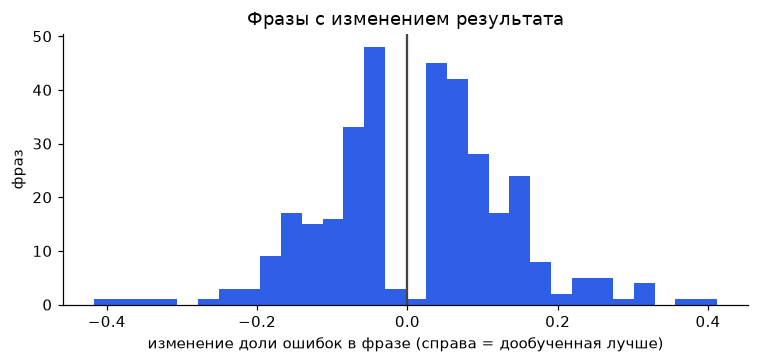

,фраз,без обучения,дообученная
bucket,,,
до 6 с,17.0,0.201,0.161
6-10 с,176.0,0.255,0.251
10-14 с,207.0,0.247,0.232
больше 14 с,100.0,0.244,0.249


,фраз,без обучения,дообученная
gender,,,
FEMALE,271.0,0.242,0.231
MALE,229.0,0.255,0.253


,фраз,без обучения,дообученная
цифры,,,
False,403.0,0.235,0.228
True,97.0,0.295,0.292


,фраз,без обучения,дообученная
латиница,,,
False,474.0,0.244,0.239
True,26.0,0.298,0.266


In [10]:
z, f = P["whisper_base_zero_shot"].copy(), P["whisper_base_finetuned"].copy()
assert (z.text.values == f.text.values).all()                   # те же фразы в том же порядке (id во FLEURS не уникальны)
z["f_err"] = f.word_errors.values; z["hyp_ft"] = f.hyp.values; z["gain"] = (z.word_errors - z.f_err) / z.ref_words.clip(lower=1)
print(f"лучше на {(z.gain > 0).sum()} фразах, хуже на {(z.gain < 0).sum()}, без изменений на {(z.gain == 0).sum()} из {len(z)}")
fig, ax = plt.subplots(figsize=(7, 3.4)); ax.hist(z.gain[z.gain != 0], bins=30, color="#2f5fe6")
ax.axvline(0, color="#444"); ax.set_xlabel("изменение доли ошибок в фразе (справа = дообученная лучше)"); ax.set_ylabel("фраз"); ax.set_title("Фразы с изменением результата")
plt.tight_layout(); plt.savefig(RESULTS / "fig_gain_hist.png", dpi=160); plt.show()

z["bucket"] = pd.cut(z.seconds, [0, 6, 10, 14, 30], labels=["до 6 с", "6-10 с", "10-14 с", "больше 14 с"])
z["цифры"] = z.text.str.contains(r"\d"); z["латиница"] = z.text.str.contains(r"[A-Za-z]")
def grp(by):
    return z.groupby(by, observed=True).apply(lambda d: pd.Series({"фраз": len(d), "без обучения": d.word_errors.sum() / d.ref_words.sum(), "дообученная": d.f_err.sum() / d.ref_words.sum()}), include_groups=False).round(3)
for by in ("bucket", "gender", "цифры", "латиница"):
    display(grp(by))

## 8. Анализ ошибок
Слова, которые изменились между двумя расшифровками, подсвечены: **красным** то, что отличается от эталона. Сначала фразы, где дообучение помогло больше всего, затем где навредило, затем самые тяжёлые.

In [11]:
def mark(ref, hyp):
    """Подсвечивает слова гипотезы, не совпавшие с эталоном (после нормализации)."""
    r, h = NORM(ref).split(), NORM(hyp).split()
    sm = difflib.SequenceMatcher(a=r, b=h, autojunk=False); bad = set()
    for tag, a1, a2, b1, b2 in sm.get_opcodes():
        if tag != "equal":
            bad |= set(range(b1, b2))
    shown = hyp.split(); nh = NORM(hyp).split()
    if len(shown) != len(nh):                    # слова с дефисом/знаками: показываем нормализованный текст
        shown = nh
    return " ".join(f'<span style="color:#dc2626;font-weight:600">{html.escape(w)}</span>' if i in bad else html.escape(w) for i, w in enumerate(shown))


def show(title, d):
    parts = [f"<h4 style='margin:14px 0 4px'>{title}</h4>"]
    for _, r in d.iterrows():
        parts.append(f"<div style='margin:6px 0;padding:8px 10px;border-left:3px solid #cbd5e1;font-size:13px;line-height:1.5'>"
                     f"<b>Эталон:</b> {html.escape(r.text)}<br><b>Без обучения:</b> {mark(r.text, r.hyp)}<br><b>Дообученная:</b> {mark(r.text, r.hyp_ft)}<br>"
                     f"<span style='color:#64748b'>ошибок слов {int(r.word_errors)} → {int(r.f_err)} из {int(r.ref_words)}</span></div>")
    display(HTML("".join(parts)))


show("Дообучение помогло больше всего", z.sort_values("gain", ascending=False).head(4))
show("Дообучение навредило", z.sort_values("gain").head(4))
show("Самые тяжёлые после дообучения", z.assign(r=z.f_err / z.ref_words.clip(lower=1)).sort_values("r", ascending=False).head(3))

**Закономерности** (по этим и остальным фразам, подробнее в `results/error_analysis.md`):
- улучшается: слитное/раздельное написание («на ездников» → «наездников»), частые слова;
- ухудшается: падежные окончания, редкие имена и названия;
- выигрыш заметнее на коротких записях (до 6 с) и записях с латиницей; на длинных (больше 14 с) дообученная чуть хуже;
- у обеих моделей в 2 из 500 фраз бывают повторяющиеся циклы («возвозвоз…»), характерный сбой генеративных моделей.

## 9. Интерпретация: куда «смотрит» декодер
Cross-attention последнего слоя декодера, усреднённая по головам. По горизонтали время записи, по вертикали токены текста. Яркая диагональ означает, что каждый токен смотрит на тот участок звука, где он произносится, то есть сеть следует за речью, а не угадывает текст по языку.


Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 245/245 [00:00<00:00, 9851.54it/s]

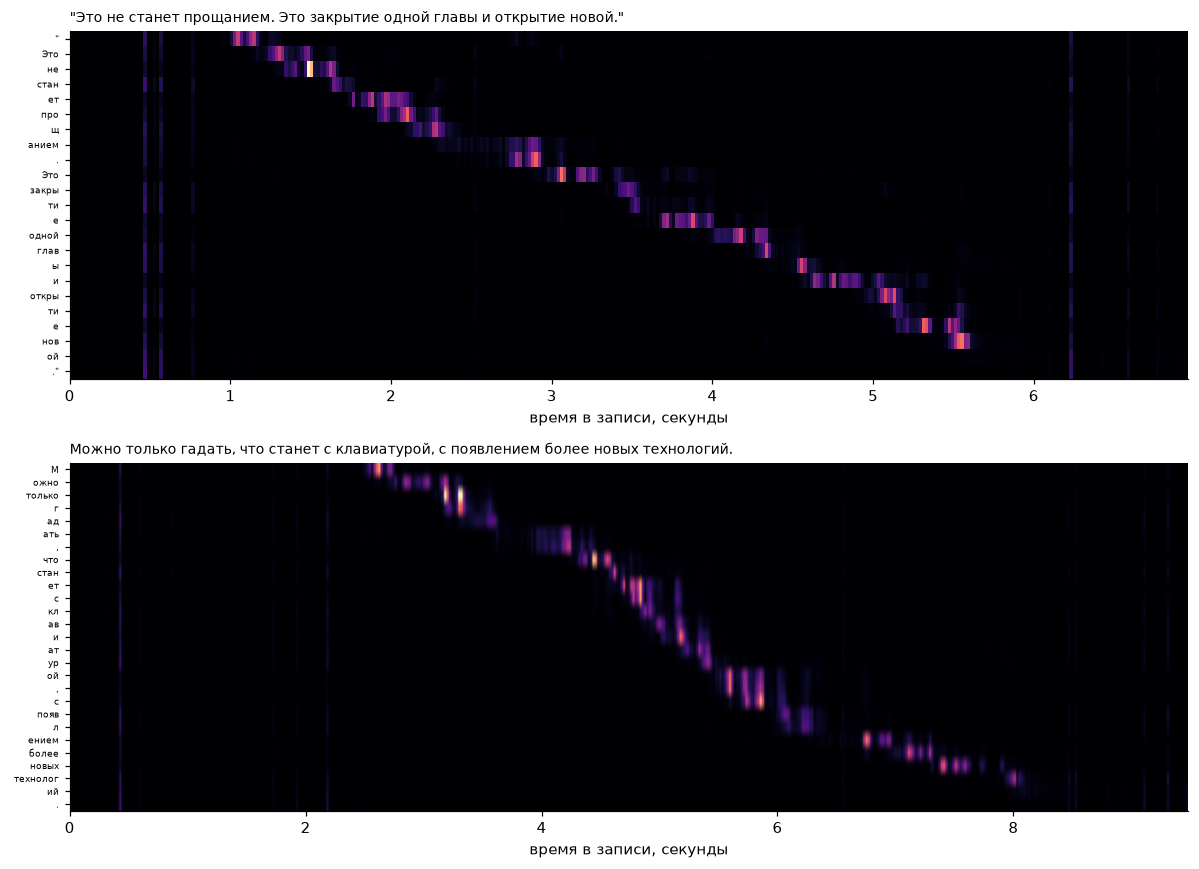

In [12]:
att_model = load_model(CKPT, attn_implementation="eager").eval()
fig, axes = plt.subplots(2, 1, figsize=(11, 8))
for ax, (_, r) in zip(axes, test.sample(2, random_state=SEED).iterrows()):
    ids = torch.tensor([proc.tokenizer(r.text).input_ids], device=DEVICE)
    with torch.no_grad():
        out = att_model(input_features=features([r.path]).to(DEVICE), decoder_input_ids=ids[:, :-1], output_attentions=True)
    att = out.cross_attentions[-1][0].mean(0).float().cpu().numpy(); frames = int(r.seconds * 50) + 1          # 50 кадров энкодера в секунду
    toks, prev = [], ""
    for i in range(ids.shape[1] - 1):
        cur = proc.tokenizer.decode(ids[0, 4:i + 1].tolist(), skip_special_tokens=False) if i >= 4 else ""
        toks.append(cur[len(prev):] if cur.startswith(prev) and "�" not in cur else "·"); prev = cur
    ax.imshow(att[4:, :frames], aspect="auto", cmap="magma", extent=[0, r.seconds, len(toks) - 4, 0])
    ax.set_yticks(np.arange(len(toks) - 4) + 0.5, toks[4:], fontsize=6); ax.set_xlabel("время в записи, секунды"); ax.set_title(r.text[:90], fontsize=9, loc="left")
plt.tight_layout(); plt.savefig(RESULTS / "fig_attention.png", dpi=160); plt.show()
del att_model

## 10. Классическая (не нейросетевая) модель: какие расшифровки ненадёжны
Для распознавания речи классической альтернативы нет, поэтому классическую модель ставим на **вспомогательную задачу**: по простым признакам расшифровки дообученной Whisper (длина, слов в секунду, доля имён с заглавной и т. п.) предсказать, что в ней WER ≥ 0,30 («нужен взгляд человека»). Обучаем на 300 валидационных фразах, тест (500) используем один раз. Сравниваем: majority-class baseline, логистическая регрессия, градиентный бустинг. Параметры выбираем 5-кратной кросс-валидацией, сгруппированной по предложению (одно предложение двух дикторов не попадёт в обе части).

доля ненадёжных расшифровок: val 0.29, test 0.32


AUC кросс-валидации
модель              настройка                            
logistic_regression C=0.03                          0.560
                    C=0.1                           0.560
                    C=0.3                           0.559
                    C=1                             0.560
                    C=3                             0.554
gradient_boosting   depth=2, lr=0.05                0.603
                    depth=2, lr=0.1                 0.611
                    depth=3, lr=0.05                0.613
                    depth=3, lr=0.1                 0.595

,настройка,AUC,95 % интервал,accuracy,F1 (ненадёжные)
majority_class,-,0.5,[0.500; 0.500],0.678,0.0
logistic_regression,C=1,0.655,[0.606; 0.708],0.664,0.52
gradient_boosting,"depth=3, lr=0.05",0.602,[0.546; 0.655],0.64,0.458


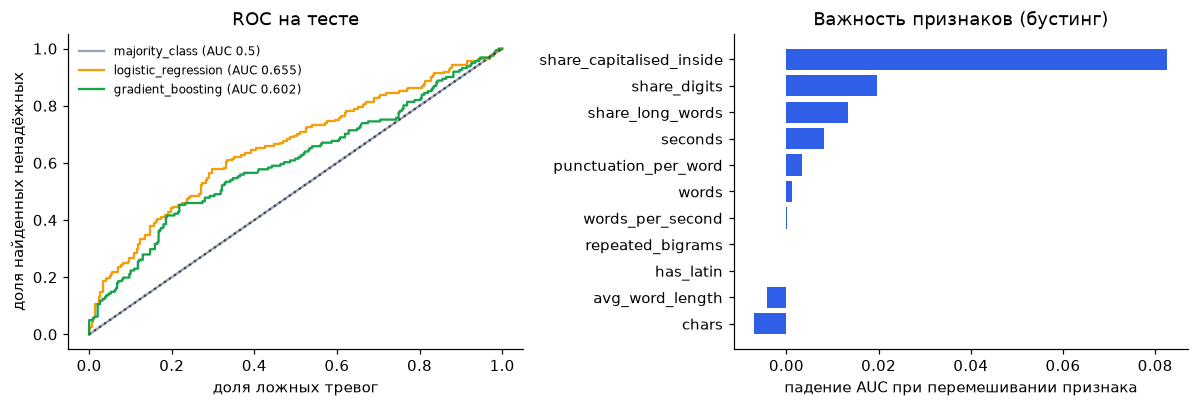

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

THRESHOLD = 0.30
FEATURES = ["seconds", "words", "chars", "words_per_second", "avg_word_length", "share_long_words", "share_capitalised_inside", "share_digits", "has_latin", "repeated_bigrams", "punctuation_per_word"]


def make_features(df):
    h = df.hyp.fillna("").astype(str); words = h.str.split(); n = words.str.len().clip(lower=1)
    f = pd.DataFrame({"seconds": df.seconds, "words": words.str.len(), "chars": h.str.len()})
    f["words_per_second"] = f.words / df.seconds; f["avg_word_length"] = f.chars / n
    f["share_long_words"] = words.apply(lambda w: np.mean([len(x) > 10 for x in w]) if w else 0)
    f["share_capitalised_inside"] = words.apply(lambda w: np.mean([x[:1].isupper() for x in w[1:]]) if len(w) > 1 else 0)       # имена людей и мест
    f["share_digits"] = words.apply(lambda w: np.mean([any(c.isdigit() for c in x) for x in w]) if w else 0)
    f["has_latin"] = h.str.contains(r"[A-Za-z]").astype(int)
    f["repeated_bigrams"] = words.apply(lambda w: len(w) - len(set(zip(w, w[1:]))) - 1 if len(w) > 2 else 0).clip(lower=0)      # зацикливание
    f["punctuation_per_word"] = h.str.count(r"[,.;:!?\"«»—-]") / n
    return f[FEATURES]


def load_xy(split):
    d = pd.read_csv(PRED / f"whisper_base_finetuned__{split}.csv")
    return make_features(d), (d.word_errors / d.ref_words.clip(lower=1) >= THRESHOLD).astype(int).to_numpy(), d.text.map(lambda t: NORM(str(t))).to_numpy()


Xv, yv, gv = load_xy("val"); Xt, yt, _ = load_xy("test")
print(f"доля ненадёжных расшифровок: val {yv.mean():.2f}, test {yt.mean():.2f}")


def cv_auc(make, X, y, groups):
    s = []
    for tr, te in GroupKFold(n_splits=5).split(X, y, groups):
        if len(set(y[tr])) < 2 or len(set(y[te])) < 2: continue
        s.append(roc_auc_score(y[te], make().fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])[:, 1]))
    return float(np.mean(s))


GRID = {"logistic_regression": [(f"C={c}", lambda c=c: make_pipeline(StandardScaler(), LogisticRegression(C=c, class_weight="balanced", max_iter=2000))) for c in (0.03, 0.1, 0.3, 1, 3)],
        "gradient_boosting": [(f"depth={d}, lr={lr}", lambda d=d, lr=lr: HistGradientBoostingClassifier(max_depth=d, learning_rate=lr, max_iter=100, class_weight="balanced", random_state=SEED)) for d in (2, 3) for lr in (0.05, 0.1)]}
best, search = {}, []
for name, opts in GRID.items():
    sc = [(lab, cv_auc(mk, Xv, yv, gv)) for lab, mk in opts]
    search += [{"модель": name, "настройка": l, "AUC кросс-валидации": round(s, 3)} for l, s in sc]
    k = max(range(len(opts)), key=lambda i: sc[i][1]); best[name] = (sc[k][0], opts[k][1])
display(pd.DataFrame(search).set_index(["модель", "настройка"]))

models = {"majority_class": DummyClassifier(strategy="most_frequent").fit(Xv, yv)} | {n: mk().fit(Xv, yv) for n, (lab, mk) in best.items()}
res = {}
for name, m in models.items():
    p = m.predict_proba(Xt)[:, 1]; pred = (p >= 0.5).astype(int)
    bs = [roc_auc_score(yt[i], p[i]) for i in (rng.integers(0, len(yt), len(yt)) for _ in range(500)) if len(set(yt[i])) > 1]
    res[name] = {"настройка": best[name][0] if name in best else "-", "AUC": round(roc_auc_score(yt, p), 3), "95 % интервал": f"[{np.percentile(bs, 2.5):.3f}; {np.percentile(bs, 97.5):.3f}]",
                 "accuracy": round(accuracy_score(yt, pred), 3), "F1 (ненадёжные)": round(f1_score(yt, pred, zero_division=0), 3)}
display(pd.DataFrame(res).T)

imp = permutation_importance(models["gradient_boosting"], Xt, yt, scoring="roc_auc", n_repeats=20, random_state=SEED); order = np.argsort(imp.importances_mean)[::-1]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, c in (("majority_class", "#94a3b8"), ("logistic_regression", "#f59e0b"), ("gradient_boosting", "#16a34a")):
    fpr, tpr, _ = roc_curve(yt, models[name].predict_proba(Xt)[:, 1]); ax[0].plot(fpr, tpr, color=c, label=f"{name} (AUC {res[name]['AUC']})")
ax[0].plot([0, 1], [0, 1], ":", color="#444"); ax[0].set_xlabel("доля ложных тревог"); ax[0].set_ylabel("доля найденных ненадёжных"); ax[0].legend(fontsize=8, frameon=False); ax[0].set_title("ROC на тесте")
ax[1].barh([FEATURES[i] for i in order][::-1], [imp.importances_mean[i] for i in order][::-1], color="#2f5fe6"); ax[1].set_xlabel("падение AUC при перемешивании признака"); ax[1].set_title("Важность признаков (бустинг)")
plt.tight_layout(); plt.savefig(RESULTS / "fig_detector.png", dpi=160); plt.show()

**Вывод.** Классические модели лишь слегка лучше случайного (AUC ≈ 0,60–0,66 против 0,5): простых признаков текста мало, чтобы надёжно угадать плохую расшифровку. Главный признак это доля слов с заглавной буквой внутри фразы (имена), что согласуется с анализом ошибок: имена и названия Whisper пишет хуже всего. Это не конкурент нейросети в распознавании, а вспомогательный инструмент; сильнее сигнал дала бы уверенность самого декодера.

## 11. Проверка экспорта и демонстрация на новой записи
Для работы в приложении веса из формата Hugging Face конвертированы в формат пакета `openai-whisper` (`08_export_openai.py`). Проверка (12 фраз): разница выходов декодера 0,0, 10 из 12 расшифровок совпали после нормализации (остальные отличаются только режимом декодирования двух библиотек).

In [14]:
print(json.dumps({k: v for k, v in json.loads((RESULTS / "export_check.json").read_text()).items() if k != "examples"}, ensure_ascii=False, indent=1))

{
 "max_abs_difference_of_logits": 0.0,
 "checked_utterances": 12,
 "identical_transcripts_after_normalisation": 10,
 "note": "openai-whisper decodes with timestamp tokens by default; this check switches them off to match the fine-tuning"
}


**Новый пример.** Запись, которой нет ни в обучении, ни в проверке, ни в тесте: русская речь, синтезированная голосом macOS (`demo/talk_ru.m4a`, только для показа). Файл режется на куски по 25 секунд (окно Whisper 30 с) и распознаётся обеими моделями.

In [15]:
demo = ROOT / "demo" / "talk_ru.m4a"
if demo.exists():
    tmp = Path(tempfile.mkdtemp()); subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(demo), "-ar", "16000", "-ac", "1", str(tmp / "d.wav")], check=True)
    a, sr = sf.read(tmp / "d.wav", dtype="float32"); step = 25 * sr; paths = []
    for i, s in enumerate(range(0, len(a), step)):
        sf.write(tmp / f"p{i}.wav", a[s:s + step], sr); paths.append(str(tmp / f"p{i}.wav"))
    print(f"запись {len(a) / sr:.0f} с, кусков: {len(paths)}")
    print("\nБез обучения:\n", " ".join(transcribe(base, paths)))
    print("\nДообученная:\n", " ".join(transcribe(ft, paths)))
else:
    print("demo/talk_ru.m4a не найден")

запись 62 с, кусков: 3


[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Без обучения:
 Здравствуйте! Сегодня мы поговорим о нейронных сетях, нейронная сеть состоит из слоев, и в каждом слое находится искусственной нейроны. Каждый нейрон складывает свои входы с весами и пропускает результат через функции активации. Главное отличие от обычных программ в том, что сеть учится на примерах, оправила вручную никто не пишет. Теперь об обучение, чтобы понять, насколько модель ошибает используют функцию потерь. Градиентный спуск постепенно, шаг за шагом, уменьшает эту ошибку. А градиенты для всех весов считают алгоритм обратного распространения ошибки. Кстати, вчера я ездил на рыбалку на озеро, поймал двух больших щуки потом долго жарил их на кастрее вместе с друзьями. Вернемся к теме, есть проблема переобучения, модель запоминает обучающие данные и плохо работают на новых данных. Один из способов борьбы называется Дропаут, он случайно отключает часть нейронов во время обучения. На этом на сегодня всё, спасибо за внимание.



Дообученная:
 Здравствуйте! Сегодня мы поговорим о нейронных сетях, нейронная сеть состоит из слоёв, и в каждом слое находится искусственной нейроны. Каждый нейрон складывает свои входы с весами и пропускает результат через функции активации, главной отличия от обычных программ в том, что сеть учится на примерах, оправила вручную никто не пишет, теперь об обучение, чтобы понять, насколько модель ошибает Агредиенты для всех весов считают алгоритм обратного распространения ошибки. Кстати, вчера я ездил на рыбалку на озеро, поймал двух больших щук и потом долго жарил их на кастрее вместе с друзьями, вернёмся к теме. Есть проблема переобучения, модель запоминает обучающий Дальше данный и плохо работает на новых данных. Один из способов борьбы называется Дропаут, он случайно отключает часть нейронов во время обучения, но это на сегодня всё, спасибо за внимание.


## 12. Выводы, ограничения, дальнейшие шаги

**Что сделано.** Реальные данные FLEURS → EDA → разбиения по разным дикторам и проверка утечки → baseline и Whisper без обучения → дообучение всей сети на PyTorch (teacher forcing, AdamW, SpecAugment, ранняя остановка) → оценка с доверительными интервалами → кривые обучения, разбор ошибок, интерпретация (cross-attention) → классическая модель для ненадёжных расшифровок → экспорт в систему DATERA EDU и демонстрация.

**Главный результат.** WER на тесте 0,2476 → 0,2408 (CER без изменений), разница статистически незначима. Дообучение маленькой модели на 4,7 часах читаемой речи почти ничего не добавило, потому что готовый Whisper уже обучен на огромном объёме русского языка.

**Ограничения.**
- Читаемая речь в тишине, энциклопедические предложения: это не живой урок (диалог, шум, дети).
- Обучен один learning rate; полный подбор гиперпараметров не сделан (≈ 35 минут на прогон).
- Тест 500 фраз: интервалы широкие; доверять можно только крупным различиям.
- Классическая модель на 300 примерах, выбор между моделями шумный.

**Что дальше.** Больше данных (диалоги, шум, детская речь) с точными расшифровками: на таком материале у готовой модели больше ошибок и эффект был бы заметнее; модель крупнее на GPU; перебор learning rate; казахский язык (у готовой модели там ошибок гораздо больше).

**Воспроизводимость.** Версии библиотек в `requirements-whisper.txt` (torch 2.15, transformers 5.24), seed 42, данные FLEURS `ru_ru` (CC BY 4.0, Hugging Face `google/fleurs`).

